# DAY2 실습 03 — 그래프와 순위

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib

In [ ]:
import os

from google.colab import drive

# Google Drive를 Colab에 연결한다. 실행하면 권한 승인 창이 나타난다 → "Google Drive에 연결" → 계정 선택 → "허용"
drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "superstore.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 데이터 준비



In [ ]:
# [예제] 01·02와 같은 주문 단위 표 만들기

orders = data.groupby("order_id", as_index=False).agg(
    region=("region", "first"),
    segment=("segment", "first"),
    주문매출=("sales", "sum"),
    주문이익=("profit", "sum")
)

print("주문 수:", len(orders), "고유 주문 수:", orders["order_id"].nunique())
display(orders.head())

주문 수: 5111 고유 주문 수: 5111


,order_id,region,segment,주문매출,주문이익
0,CA-2023-100867,West,Home Office,32.700,8.5000
1,CA-2023-107153,East,Corporate,10.688,3.7408
2,CA-2023-115238,East,Corporate,281.160,89.2000
3,CA-2023-115777,East,Consumer,387.990,182.3600
4,CA-2023-117964,East,Corporate,56.424,-18.5354


In [ ]:
# [예제] 01의 지역별 주문매출 요약표 (n · 합계 · 평균 · 중앙값 · 표준편차 · Q1 · Q3 · IQR)

group = orders.groupby("region")["주문매출"]
summary = group.agg(n="size", 합계="sum", 평균="mean", 중앙값="median", 표준편차="std")
summary["Q1"] = group.quantile(0.25)
summary["Q3"] = group.quantile(0.75)
summary["IQR"] = summary["Q3"] - summary["Q1"]
display(summary)

,n,합계,평균,중앙값,표준편차,Q1,Q3,IQR
region,,,,,,,,
Central,1179,503170.6728,426.777500,133.896,962.090329,31.8270,479.9560,448.1290
East,1475,691828.1680,469.036046,142.920,966.378967,37.6800,515.6535,477.9735
South,822,391721.9050,476.547330,159.975,1144.589920,34.5405,536.1100,501.5695
West,1635,739813.6085,452.485387,161.568,807.569781,42.2620,505.4840,463.2220


## 1. 그래프 고르기

그래프는 **시각화 목적**(무엇을 비교하거나 확인하려는가)으로 고르고, 그래프에 넣을 **입력 데이터**(원자료를 그대로 쓰는지, 집계한 표를 쓰는지)를 먼저 준비한다.

| 시각화 목적 | 그래프 | 입력 데이터 | 예 |
|---|---|---|---|
| 집단마다 얼마나 큰가 (합계·평균) | 막대그래프 | 집단별 요약표 (groupby) | 지역별 총매출과 주문당 평균매출 |
| 두 기준의 조합마다 몇 건인가 | 묶은 막대그래프 | 교차표 (건수) | 지역 × 고객군 주문 수 |
| 집단 안에서 어떻게 나뉘는가 | 100% 누적막대그래프 | 교차표 (행 비율) | 지역별 고객군 구성비 |
| 집단마다 분포가 다른가 | 박스플롯 | 원자료 (주문 단위 orders) | 지역별 주문매출 분포 |
| 두 기준의 조합마다 평균이 어떤가 | 히트맵 | 피벗표 (평균) | 지역 × 고객군 주문당 평균매출 |
| 몇 번째인가 | 정렬·순위 표 | 요약표 | 지역별 총매출 순위와 평균 순위 |

## 2. 그래프별 도구 고르기

| 그래프 | Pandas | Matplotlib | Seaborn | 선택한 도구와 이유 |
|---|---|---|---|---|
| 막대 (집계한 값) | `Series.plot.bar()` | `plt.bar(x, height)` | `sns.barplot()` | **Pandas** : 요약표의 열에서 바로 그린다 |
| 묶은 막대 | `DataFrame.plot.bar()` (열마다 막대) | `plt.bar()`를 위치를 옮겨 여러 번 | `sns.countplot(x=, hue=)` | 이미 만든 **교차표가 있으면 Pandas**, **원자료에서 바로 세려면 Seaborn** |
| 100% 누적막대 | `DataFrame.plot.bar(stacked=True)` | `plt.bar(bottom=)`로 한 층씩 직접 쌓기 | 전용 함수 없음 | **Pandas** : `stacked=True` 한 줄 |
| 집단별 박스플롯 | `DataFrame.boxplot(column=, by=)` | `plt.boxplot([집단별 목록], tick_labels=)` | `sns.boxplot(data=, x=, y=)` | **Seaborn** : 열 이름만 넣으면 집단마다 상자를 그린다 |
| 히트맵 | 미지원 | `plt.imshow()` + 칸마다 `plt.text()` | `sns.heatmap(annot=True)` | **Seaborn** : 색과 칸 숫자를 한 번에 |
| 여러 그래프 나란히 · 꾸미기 | — | `plt.subplots()`, `ax.set()`, `ax.bar_label()` | — | **Matplotlib** : 어느 도구로 그린 그래프에도 쓴다 |

**고르는 기준**
- 집계한 표(요약표·교차표)가 이미 있으면 → **Pandas** `.plot.bar()`
- 원자료에서 집단별로 바로 세거나 분포를 그리려면 → **Seaborn** (`countplot`, `boxplot`)
- 칸마다 숫자를 적은 색 표가 필요하면 → **Seaborn** `heatmap`
- 그래프를 나란히 놓거나 제목·축·숫자 표시를 다듬으려면 → **Matplotlib**

공식 문서 : [DataFrame.plot.bar](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html) · [seaborn.countplot](https://seaborn.pydata.org/generated/seaborn.countplot.html) · [seaborn.boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html) · [seaborn.heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html) · [pyplot.subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html)

## 3. 막대그래프 : 합계와 평균

합계는 집단의 **규모**를, 평균은 **1건당 수준**을 보여 준다. 합계가 큰 지역이 주문당 평균도 높다는 보장은 없다. 두 지표는 단위와 크기가 달라(합계는 수십만, 평균은 수백) 한 그래프의 같은 세로축에 그리지 않고, 그래프 두 개를 나란히 놓는다.

막대그래프의 세로축은 0에서 시작해야 막대 높이로 크기를 정직하게 비교할 수 있다. Pandas `.plot.bar()`는 기본으로 0에서 시작한다.

**[Matplotlib] `plt.subplots(행 수, 열 수, figsize=(가로, 세로))`** — 그래프 칸 여러 개를 한 번에 만든다

| 돌려주는 값 | 뜻 |
|---|---|
| `fig` | 그림 전체 |
| `axes[0]`, `axes[1]` | 왼쪽 칸, 오른쪽 칸 (1행 2열일 때) |

**[Pandas] `.plot.bar()` 옵션**

| 옵션 | 하는 일 | 예 |
|---|---|---|
| `ax` | 그릴 칸 지정 | `ax=axes[0]` |
| `rot` | 가로축 글자 각도 | `rot=0` (눕히지 않음) |
| `color` | 막대 색 | `color="steelblue"` |

**[Matplotlib] `ax.set()` 옵션** — 칸 하나의 제목과 축을 정한다

| 옵션 | 하는 일 |
|---|---|
| `title` | 그래프 제목 |
| `xlabel`, `ylabel` | 가로축·세로축 이름 (단위를 같이 적는다) |
| `ylim` | 세로축 범위 `(최솟값, 최댓값)` |

`plt.tight_layout()`은 칸끼리 글자가 겹치지 않게 간격을 맞춘다.

공식 문서 : [Series.plot.bar](https://pandas.pydata.org/docs/reference/api/pandas.Series.plot.bar.html) · [pyplot.subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html) · [Axes.set](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set.html)

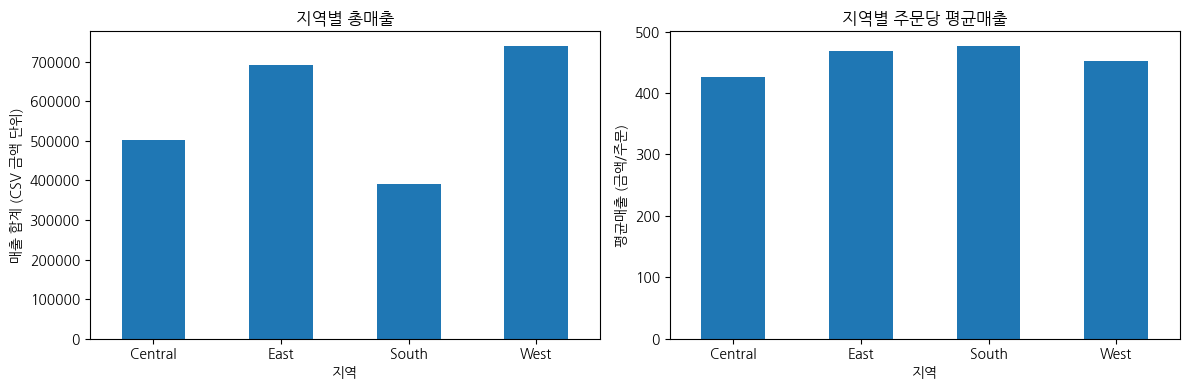

In [ ]:
# [실습]
# 상황 : 지역별 실적을 보고할 때 '규모'와 '1건당 수준' 중 무엇이 1위인지 구분해 보여 주려 한다.
# 지역별 총매출과 주문당 평균매출을 막대그래프 두 개로 나란히 그리시오.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
summary["합계"].plot.bar(ax=axes[0], rot=0)
summary["평균"].plot.bar(ax=axes[1], rot=0)
axes[0].set(title="지역별 총매출", xlabel="지역", ylabel="매출 합계 (CSV 금액 단위)")
axes[1].set(title="지역별 주문당 평균매출", xlabel="지역", ylabel="평균매출 (금액/주문)")
plt.tight_layout()
plt.show()

## 4. 묶은 막대와 100% 누적막대

교차표를 그림으로 바꿀 때는 **건수를 비교하는지, 구성을 비교하는지**부터 정한다.

| 그래프 | 막대가 나타내는 것 | 입력 데이터 | 답하는 질문 |
|---|---|---|---|
| 묶은 막대그래프 (grouped bar) | 조합별 **건수** | 교차표 (건수) | 어느 지역·고객군 조합의 주문이 많은가? |
| 100% 누적막대그래프 | 집단 안의 **구성비** | 교차표 행 비율 (02의 `normalize="index"`) | 지역마다 고객군 구성이 어떻게 다른가? |

**[Pandas] `DataFrame.plot.bar()` 옵션** — 표의 열 하나하나를 막대로 그린다

| 옵션 | 하는 일 | 예 |
|---|---|---|
| `stacked` | `False`(기본) 나란히 / `True` 한 막대에 쌓기 | `stacked=True` |
| `rot` | 가로축 글자 각도 | `rot=0` |
| `figsize` | 그림 크기 | `figsize=(10, 4)` |

**[Seaborn] `sns.countplot()` 옵션** — 원자료의 행 수를 직접 세어 막대로 그린다

| 옵션 | 하는 일 | 예 |
|---|---|---|
| `data` | 사용할 표 | `data=orders` |
| `x` | 가로축 범주 열 | `x="region"` |
| `hue` | 막대를 나눠 색으로 구분할 열 | `hue="segment"` |
| `order`, `hue_order` | 가로축·색 구분의 순서 | `order=["Central", "East", "South", "West"]` |

**[Matplotlib] 범례와 숫자 표시**

| 코드 | 하는 일 |
|---|---|
| `ax.legend(title="이름")` | 범례 제목 |
| `ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")` | 범례를 그래프 오른쪽 밖에 둔다 (막대를 가릴 때) |
| `ax.bar_label(막대묶음, fmt="%.1f%%", label_type="center")` | 막대 안에 값을 적는다. `ax.containers`에 색(고객군)별 막대 묶음이 들어 있다 |

공식 문서 : [DataFrame.plot.bar](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html) · [seaborn.countplot](https://seaborn.pydata.org/generated/seaborn.countplot.html) · [Axes.bar_label](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bar_label.html)

segment,Consumer,Corporate,Home Office
region,,,
Central,608,348,223
East,741,468,266
South,444,247,131
West,835,489,311


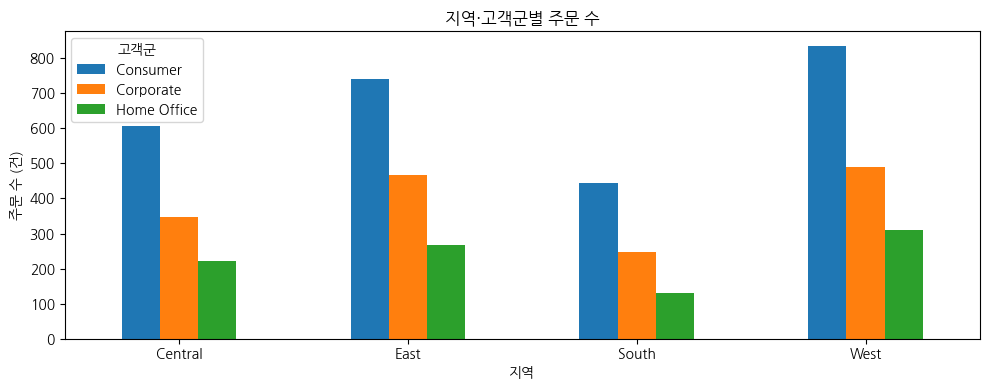

In [ ]:
# [예제] [Pandas] 묶은 막대그래프 : 이미 만든 교차표에서 그리기
# crosstab 결과(지역 × 고객군 주문 수)의 열(고객군)마다 막대가 하나씩 생긴다

ct = pd.crosstab(orders["region"], orders["segment"])
display(ct)

ax = ct.plot.bar(figsize=(10, 4), rot=0)
ax.set(title="지역·고객군별 주문 수", xlabel="지역", ylabel="주문 수 (건)")
ax.legend(title="고객군")
plt.tight_layout()
plt.show()

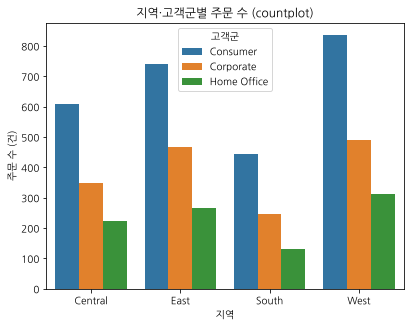

In [ ]:
# [실습]
# 상황 : 교차표를 따로 만들지 않고, 주문 원자료(orders)에서 바로 지역 × 고객군 주문 수 그래프를 그리려 한다.
# sns.countplot() 으로 위 예제와 같은 묶은 막대그래프를 그리시오.

ax = sns.countplot(data=orders, x="region", hue="segment",
                   order=["Central", "East", "South", "West"],
                   hue_order=["Consumer", "Corporate", "Home Office"])
ax.set(title="지역·고객군별 주문 수 (countplot)", xlabel="지역", ylabel="주문 수 (건)")
ax.legend(title="고객군")
plt.show()

segment,Consumer,Corporate,Home Office
region,,,
Central,51.57,29.52,18.91
East,50.24,31.73,18.03
South,54.01,30.05,15.94
West,51.07,29.91,19.02


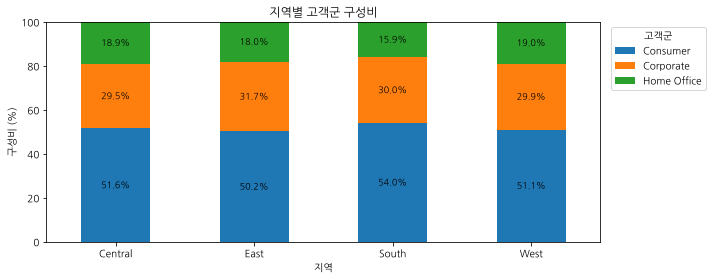

In [ ]:
# [실습]
# 상황 : 지역 담당자가 '우리 지역 주문 중 고객군 구성'이 다른 지역과 다른지 한눈에 보려 한다.
# 지역별 고객군 구성비(행 비율)를 100% 누적막대그래프로 그리고, 막대 안에 구성비(%)를 적으시오.

# 1. 지역별 고객군 구성비(%) : 02의 행 비율
row_rate = pd.crosstab(orders["region"], orders["segment"], normalize="index") * 100
display(row_rate.round(2))

# 2. 100% 누적막대그래프
ax = row_rate.plot.bar(stacked=True, figsize=(10, 4), rot=0)

# 3. 막대 안에 구성비(%) 표시
#    ax.containers : 고객군(색)별 막대 묶음 / bar_label : 막대에 값을 적는다
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", fontsize=9)

ax.set(title="지역별 고객군 구성비", xlabel="지역", ylabel="구성비 (%)", ylim=(0, 100))
ax.legend(title="고객군", bbox_to_anchor=(1.01, 1), loc="upper left")   # 범례를 그래프 오른쪽 밖에 둔다
plt.tight_layout()
plt.show()

## 5. 집단별 박스플롯

박스플롯은 집단마다 **중앙값 · 사분위수 · 이상값 후보**를 한 상자로 요약해 분포를 비교한다. 집단별 박스플롯은 아래 순서로 읽는다.

1) **중앙값** (상자 안 선) : 집단의 대표 수준을 먼저 본다
2) **IQR** (상자 길이) : 가운데 50%가 얼마나 퍼졌는지 비교한다
3) **수염 · 점** : 수염 밖 점은 이상값 후보다. 큰 값이 있으면 원자료로 확인한다
4) **n 확인** : 집단별 건수(n)를 함께 확인한다.

**[Seaborn] `sns.boxplot()` 옵션**

| 옵션 | 하는 일 | 예 |
|---|---|---|
| `data` | 사용할 표 | `data=orders` |
| `x`, `y` | 가로축 범주 열, 세로축 숫자 열 | `x="region"`, `y="주문매출"` |
| `order` | 상자 순서 | `order=["Central", "East", "South", "West"]` |
| `showfliers` | `False`이면 이상값 후보 점을 그리지 않는다 (데이터는 그대로) | `showfliers=False` |
| `ax` | 그릴 칸 지정 | `ax=axes[0]` |



공식 문서 : [seaborn.boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html) · [DataFrame.boxplot](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.boxplot.html)

In [ ]:
# [실습]
# 상황 : 지역별 '주문'의 크기와 퍼짐을 비교하려 한다. 큰 주문 때문에 상자가 눌려 보이므로 이상값 후보를 숨긴 그림도 함께 본다.
# 지역별 주문매출 박스플롯을 이상값 후보 표시(왼쪽)와 숨김(오른쪽)으로 나란히 그리고, summary 의 n·중앙값·IQR 과 함께 읽으시오.

region_order = ["Central", "East", "South", "West"]
display(summary[["n", "중앙값", "Q1", "Q3", "IQR"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=orders, x="region", y="주문매출", order=region_order, ax=axes[0])
sns.boxplot(data=orders, x="region", y="주문매출", order=region_order, showfliers=False, ax=axes[1])
axes[0].set(title="주문매출 : 이상값 후보 표시", xlabel="지역", ylabel="주문매출 (CSV 금액 단위)")
axes[1].set(title="주문매출 : 이상값 후보 숨김", xlabel="지역", ylabel="주문매출 (CSV 금액 단위)")
plt.tight_layout()
plt.show()

## 6. 히트맵

**히트맵**(heatmap)은 표의 숫자 크기를 색으로 칠한 그래프다. 행 × 열 표(피벗표)를 그대로 그려, 어느 칸이 크고 작은지 색으로 먼저 찾고 칸 안의 숫자로 확인한다.

**[Seaborn] `sns.heatmap()` 옵션**

| 옵션 | 하는 일 | 예 |
|---|---|---|
| 첫 번째 값 | 칠할 행 × 열 표 | `pivot` |
| `annot` | `True`이면 칸마다 숫자를 적는다 | `annot=True` |
| `fmt` | 칸 숫자 형식 | `".1f"` 소수 첫째 자리, `"d"` 정수 |
| `cmap` | 색 묶음 (생략하면 기본 색) | `cmap="YlGnBu"` |

색 막대(colorbar)는 자동으로 붙는다. Matplotlib으로 그리려면 `plt.imshow()`로 색을 칠한 뒤 칸마다 `plt.text()`로 숫자를 적어야 하고, Pandas에는 히트맵 함수가 없다.

공식 문서 : [seaborn.heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html) · [DataFrame.pivot_table](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot_table.html)

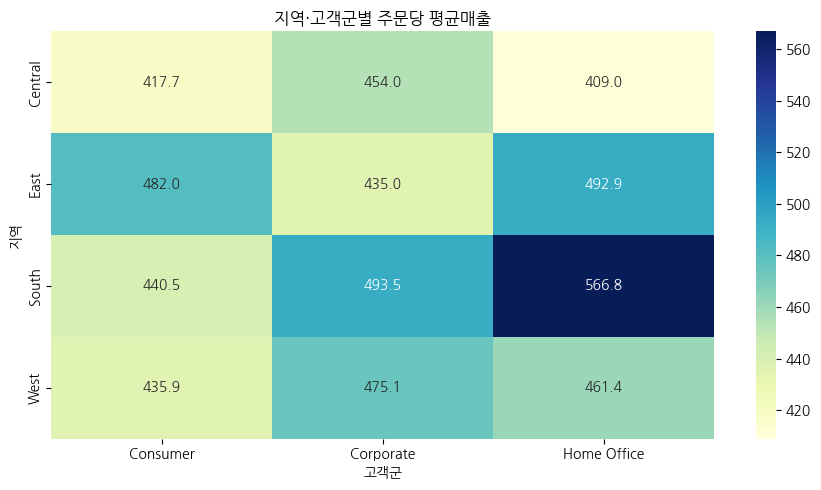

In [ ]:
# [실습]
# 상황 : 지역 × 고객군 12개 조합 중 주문당 평균매출이 높은 조합과 낮은 조합을 한눈에 찾으려 한다.
# 지역 × 고객군 주문당 평균매출 피벗표를 만들고 히트맵으로 그리시오. 칸마다 숫자를 소수 첫째 자리까지 적으시오.

# 1. 지역(region)과 고객군(segment)별 주문당 평균매출 계산 (02의 피벗표)
pivot = orders.pivot_table(
    index="region",      # 행: 지역
    columns="segment",   # 열: 고객군
    values="주문매출",    # 계산할 값: 주문매출
    aggfunc="mean"       # 평균 계산
)
plt.figure(figsize=(9, 5))

sns.heatmap(
    pivot,            # 평균매출 피벗표
    annot=True,       # 셀 안에 숫자 표시
    fmt=".1f",        # 소수점 첫째 자리까지 표시
    cmap="YlGnBu"     # 색상표 지정 (노랑 → 초록 → 파랑). 대소문자를 구분한다
)

plt.title("지역·고객군별 주문당 평균매출")
plt.xlabel("고객군")
plt.ylabel("지역")

plt.tight_layout()
plt.show()

### 직접 해보기

같은 모양으로 칸마다 주문 수(n)를 칠한 히트맵을 그리고, 평균이 가장 높은 칸의 건수를 확인한다.

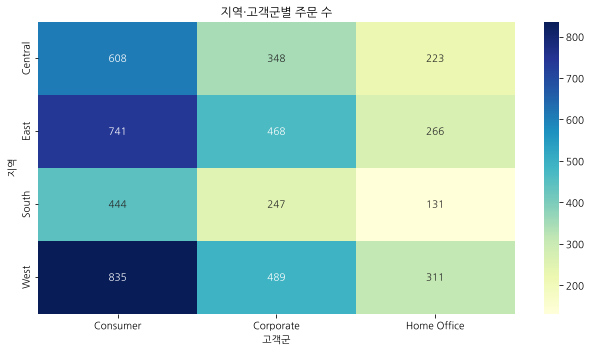

In [ ]:
# [실습]
# 상황 : '평균매출이 가장 높은 조합'을 보고하기 전에, 그 칸에 주문이 충분히 들어 있는지 확인하려 한다.
# 지역 × 고객군 주문 수 피벗표(aggfunc="count")를 만들고 히트맵으로 그리시오. 칸 숫자는 정수(fmt="d")로 적으시오.

pivot_n = orders.pivot_table(index="region", columns="segment", values="주문매출", aggfunc="count")

plt.figure(figsize=(9, 5))
sns.heatmap(pivot_n, annot=True, fmt="d", cmap="YlGnBu")
plt.title("지역·고객군별 주문 수")
plt.xlabel("고객군")
plt.ylabel("지역")
plt.tight_layout()
plt.show()

## 7. 정렬과 순위

**정렬**은 행을 값의 크기 순서로 **보여 주는 순서만** 바꾼다. **순위**는 각 값이 **몇 번째인지**를 새 열로 붙인다. 정렬한 표는 위에서부터 읽으면 되고, 순위 열은 표를 다른 순서로 놓아도 몇 위인지 남는다.

### 동점일 때 순위 매기는 방법

예) 매출 500 · 400 · 400 · 200 (큰 값이 1위)

| method | 동점 처리 | 결과 | 쓰는 때 |
|---|---|---|---|
| `"average"` (기본값) | 동점끼리 순위의 평균을 준다 | 1 · 2.5 · 2.5 · 4 | 통계 계산에 순위를 쓸 때 |
| `"min"` | 동점에 가장 높은 순위를 주고, 다음 순위는 건너뛴다 | 1 · 2 · 2 · 4 | 보고서·경기 순위처럼 '공동 2위 다음은 4위' |
| `"dense"` | 동점에 같은 순위를 주고, 다음 순위를 건너뛰지 않는다 | 1 · 2 · 2 · 3 | '몇 번째 등급인가'처럼 순위가 이어져야 할 때 |

### 평균 순위는 n과 함께 읽는다

같은 집단도 지표에 따라 순위가 달라진다. 특히 평균 순위는 건수가 적은 집단에서 큰 값 몇 개에 쉽게 바뀌므로, n과 중앙값 순위를 함께 본다.

**[Pandas] 옵션**

| 함수 | 옵션 | 하는 일 |
|---|---|---|
| `sort_values("열")` | `ascending=False` | 큰 값부터 정렬 (기본 `True`는 작은 값부터) |
| `rank()` | `ascending=False` | 큰 값에 1위를 준다 (기본 `True`는 작은 값이 1위) |
| `rank()` | `method` | 동점 처리 방법 (`"average"`, `"min"`, `"dense"`) |

`rank()`의 결과는 `1.0`, `2.0`처럼 실수로 나온다. 정수로 보려면 `.astype(int)`를 붙인다 (동점 평균 2.5 같은 값이 없을 때).

공식 문서 : [DataFrame.sort_values](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html) · [Series.rank](https://pandas.pydata.org/docs/reference/api/pandas.Series.rank.html)

In [ ]:
# [예제] [Pandas] 동점이 있을 때 세 가지 순위 방법
sales = pd.Series([500, 400, 400, 200], index=["A지역", "B지역", "C지역", "D지역"])

rank_demo = pd.DataFrame({
    "매출": sales,
    "average": sales.rank(ascending=False, method="average"),
    "min": sales.rank(ascending=False, method="min"),
    "dense": sales.rank(ascending=False, method="dense"),
})
rank_demo

,매출,average,min,dense
A지역,500,1.0,1.0,1.0
B지역,400,2.5,2.0,2.0
C지역,400,2.5,2.0,2.0
D지역,200,4.0,4.0,3.0


### 직접 해보기

지역별 총매출 · 주문당 평균매출 · 주문당 중앙값 매출의 순위를 각각 구하고, 총매출이 큰 순서로 정렬해 세 순위를 비교한다.

In [ ]:
# [실습]
# 상황 : '매출 1위 지역'을 보고하려 한다. 어떤 지표로 1위를 정하느냐에 따라 결과가 달라지는지 확인한다.
# summary 로 총매출·평균·중앙값 순위(큰 값이 1위, method="min")를 구하고, 총매출이 큰 순서로 정렬해 n 과 함께 출력하시오.

rank_table = summary[["n", "합계", "평균", "중앙값"]].copy()
rank_table["총매출 순위"] = rank_table["합계"].rank(ascending=False, method="min").astype(int)
rank_table["평균 순위"] = rank_table["평균"].rank(ascending=False, method="min").astype(int)
rank_table["중앙값 순위"] = rank_table["중앙값"].rank(ascending=False, method="min").astype(int)

display(rank_table.sort_values("합계", ascending=False).round(1))

,n,합계,평균,중앙값,총매출 순위,평균 순위,중앙값 순위
region,,,,,,,
West,1635,739813.6,452.5,161.6,1,3,1
East,1475,691828.2,469.0,142.9,2,2,3
Central,1179,503170.7,426.8,133.9,3,4,4
South,822,391721.9,476.5,160.0,4,1,2


## 8. 정리

| 시각화 목적 | 그래프 | 도구 · 함수 | 입력 데이터 |
|---|---|---|---|
| 집단별 합계·평균 | 막대그래프 | [Pandas] `.plot.bar()` | 요약표 |
| 여러 그래프 나란히 | — | [Matplotlib] `plt.subplots()` + `ax=` | — |
| 조합별 건수 | 묶은 막대그래프 | [Pandas] `DataFrame.plot.bar()` / [Seaborn] `sns.countplot(hue=)` | 교차표 / 원자료 |
| 집단 안의 구성 | 100% 누적막대그래프 | [Pandas] `.plot.bar(stacked=True)` | 교차표 행 비율 |
| 막대에 값 적기 | — | [Matplotlib] `ax.bar_label()` | — |
| 집단별 분포 | 박스플롯 | [Seaborn] `sns.boxplot(x=, y=)` | 원자료 |
| 조합별 평균·건수 | 히트맵 | [Seaborn] `sns.heatmap(annot=True)` | 피벗표 |
| 몇 번째인가 | 정렬·순위 | [Pandas] `sort_values()`, `rank(method=)` | 요약표 |

순서
1) 시각화 목적을 정한다 : 무엇을 비교·확인할지 정하고, 막대 높이·색이 나타낼 값(건수 · 비율 · 평균)을 정한다
2) 입력 데이터를 준비한다 : 목적에 맞게 요약표 · 교차표 · 피벗표를 만들거나 원자료를 그대로 쓴다
3) 도구를 고른다 : 집계한 표는 Pandas, 원자료에서 바로 그리는 집단 비교는 Seaborn, 배치와 꾸미기는 Matplotlib
4) 순위는 기준 지표를 밝혀 보고한다 : 지표마다 순위가 달라질 수 있으며, 평균 순위는 n · 중앙값과 함께 해석한다

공식 문서 : [DataFrame.plot.bar](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html) · [seaborn.boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html) · [seaborn.heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html) · [Series.rank](https://pandas.pydata.org/docs/reference/api/pandas.Series.rank.html)

## 9. 종합 실습 : 지역별 수익성 비교

02에서 정한 적자 주문(주문이익 < 0)으로 지역별 수익성을 그래프와 순위로 비교한다. 이익이 적자인 주문의 비율(적자율)과 주문당 평균이익이 같은 지역을 가리키는지 확인한다.

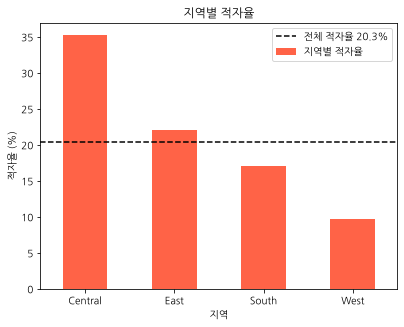

In [ ]:
# 문제 1)
# 상황 : 지역별 적자율을 막대그래프로 보고하면서, 회사 전체 적자율보다 높은 지역을 함께 표시하려 한다.
# orders 에 적자여부(0/1) 열을 만들고, 지역별 적자율(%) 막대그래프에 전체 적자율 가로선을 그리시오.

orders["적자여부"] = (orders["주문이익"] < 0).astype(int)
loss_rate = (orders.groupby("region")["적자여부"].mean() * 100).rename("지역별 적자율")   # rename : 범례에 보일 이름
overall = orders["적자여부"].mean() * 100

ax = loss_rate.plot.bar(rot=0, color="tomato")
ax.axhline(overall, color="black", linestyle="--", label=f"전체 적자율 {overall:.1f}%")
ax.set(title="지역별 적자율", xlabel="지역", ylabel="적자율 (%)")
ax.legend()
plt.show()

In [ ]:
# 문제 2)
# 지역별 주문당 평균이익 순위(큰 값이 1위)와 적자율 순위(작은 값이 1위)를 구해 한 표로 비교하시오.

profit_table = orders.groupby("region").agg(평균이익=("주문이익", "mean"), 적자율=("적자여부", "mean"))
profit_table["적자율"] = profit_table["적자율"] * 100
profit_table["평균이익 순위"] = profit_table["평균이익"].rank(ascending=False, method="min").astype(int)
profit_table["적자율 순위"] = profit_table["적자율"].rank(ascending=True, method="min").astype(int)
profit_table.round(2)

,평균이익,적자율,평균이익 순위,적자율 순위
region,,,,
Central,33.81,35.20,4,4
East,64.33,22.10,2,3
South,56.87,17.03,3,2
West,67.77,9.72,1,1
